In [1]:
import os, datetime, traceback
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

In [2]:
import akshare as ak

d:\software\python\python38\lib\site-packages\akshare\__init__.py:2645: UserWarning: 为了支持更多特性，请将 Python 升级到 3.9 及以上版本！
  warnings.warn(


In [294]:
plt.rcParams['figure.figsize'] = [12, 6]

In [3]:
from lutils.stock import LTdxHq

In [4]:
%matplotlib inline

In [5]:
ltdxhq = LTdxHq() # heartbeat=True)

In [6]:
ltdxhq.get_k_data_daily(code='113510', start='2020-01-01', qfq=False)

In [7]:
bond_zh_cov_df = ak.bond_zh_cov()

In [8]:
# bond_zh_cov_df[bond_zh_cov_df['转股价'].notnull() & bond_zh_cov_df['上市时间'].notnull()].sort_values(['转股溢价率']) # 目前可用转股价

In [9]:
bond_zh_cov_df[:2] # [bond_zh_cov_df['债券代码'] == '1110'] # [bond_zh_cov_df['债券简称'] == '宝安转债'] [bond_zh_cov_df['债券代码'] == '113510']

,债券代码,债券简称,申购日期,申购代码,申购上限,正股代码,正股简称,正股价,转股价,转股价值,债现价,转股溢价率,原股东配售-股权登记日,原股东配售-每股配售额,发行规模,中签号发布日,中签率,上市时间
0,123238,卡倍转02,2024-01-11,370863,100,300863,卡倍亿,46.19,49.01,94.2461,100.0,6.11,2024-01-10,5.9518,5.29,2024-01-15,NaN,NaT
1,123237,佳禾转债,2024-01-04,370793,100,300793,佳禾智能,19.08,21.75,87.7241,100.0,13.99,2024-01-03,2.9670,10.04,2024-01-08,0.004231,NaT


In [10]:
bond_zh_hs_cov_daily_df = ak.bond_zh_hs_cov_daily(symbol="sh113510") # sh113510 sh110026 sh111018 sz123223 sh113655  sh118046  113680 113655 113644

In [11]:
bond_zh_hs_cov_daily_df.date

0      2018-07-13
1      2018-07-16
2      2018-07-17
3      2018-07-18
4      2018-07-19
          ...    
407    2020-03-18
408    2020-03-19
409    2020-03-20
410    2020-03-23
411    2020-03-24
Name: date, Length: 412, dtype: object

In [12]:
bond_zh_hs_cov_daily_df[bond_zh_hs_cov_daily_df.date >= pd.to_datetime('2025-01-01').date()].empty

True

In [13]:
save_root = 'E:/convertible/b'

In [14]:
ltdxhq = LTdxHq()

In [15]:
list_df = ltdxhq.stock_list()

In [16]:
list_df[list_df.code == '113680'].sse.iloc[0]

'sh'

In [17]:
def _select_market_code(code):
        code = str(code)
        if code[0] in ['5', '6', '9'] or code[:3] in ["009", "126", "110", "201", "202", "203", "204", '110', '113'] or code[:4] in ['1180'] or code[:5] in ['11100'] or code[:5] in ['11101']:
            return 'sh' # 1
        return 'sz' # 0

In [18]:
# market = _select_market_code(code)

In [19]:
def fetch_by_code(row):
    try:
        code = row['债券代码']
        # if code in list_df.code.values:
        # market = list_df[list_df.code == code].sse.iloc[0]
        market = _select_market_code(code)
            
        code = '%s%s' % (market, code)
        print(code)
    
        save_path = os.path.join(save_root, '%s.csv' % code)
        df = ak.bond_zh_hs_cov_daily(symbol=code)

        if not df.empty:
            df = df[df.date >= pd.to_datetime('2018-01-01').date()]
            if not df.empty:
                df.to_csv(path_or_buf=save_path)
                
        # else:
        #     print('code pass: %s' % code)
    except:
        print('error %s' % row['债券代码'])
        # traceback.print_exc()
    


In [20]:
# bond_zh_cov_df.apply(fetch_by_code, axis=1)

In [21]:
ltdxhq.get_k_data_daily(code='118000', qfq=False)

In [22]:
list_df = ltdxhq.stock_list()

In [23]:
list_df[list_df.code.str.startswith('11101')] #  == '404002'

,code,volunit,decimal_point,name,pre_close,sse
529,111010,10,4,立昂转债,1.040590e+02,sh
530,111011,10,4,冠盛转债,1.306090e+02,sh
531,111012,10,4,福新转债,1.299660e+02,sh
532,111013,10,4,新港转债,1.229850e+02,sh
533,111014,10,4,李子转债,1.122250e+02,sh
534,111015,10,4,东亚转债,1.248400e+02,sh
535,111016,10,4,神通转债,1.273220e+02,sh
536,111017,10,4,蓝天转债,1.299980e+02,sh
944,111018,10,4,华康转债,5.877472e-39,sh


In [24]:
bond_zh_cov_value_analysis_df = ak.bond_zh_cov_value_analysis(symbol='123234')

In [25]:
bond_zh_cov_value_analysis_df

,日期,收盘价,纯债价值,转股价值,纯债溢价率,转股溢价率
0,2023-12-11,100.000,74.138596,95.015576,34.882511,5.245902
1,2023-12-12,100.000,74.180568,94.236760,34.806193,6.115702
2,2023-12-13,100.000,74.264973,94.236760,34.652981,6.115702
3,2023-12-14,100.000,74.374793,94.080997,34.454156,6.291391
4,2023-12-15,100.000,74.349693,93.613707,34.499547,6.821963
5,2023-12-18,100.000,74.412677,90.498442,34.385704,10.499139
6,2023-12-19,100.000,74.562776,91.277259,34.115177,9.556314
7,2023-12-20,100.000,74.591613,90.809969,34.063330,10.120069
8,2023-12-21,100.000,74.652085,93.146417,33.954732,7.357860
9,2023-12-22,100.000,74.750412,92.523364,33.778527,8.080808


In [26]:
file_path = 'E:/convertible/d/sz123234.csv'

In [27]:
df = pd.read_csv(file_path, index_col=0, parse_dates=['date'])

In [28]:
df['date'].iloc[-1]

Timestamp('2024-01-08 00:00:00')

In [29]:
# df = df.set_index(pd.to_datetime(df['date']), drop=True, inplace=False)

In [30]:
df['date']

0   2023-12-29
1   2024-01-02
2   2024-01-03
3   2024-01-04
4   2024-01-05
5   2024-01-08
Name: date, dtype: datetime64[ns]

In [31]:
bond_zh_cov_value_analysis_df = ak.bond_zh_cov_value_analysis(symbol="123234")
# .rename(columns={
#     '日期': 'date', 
#     '收盘价': 'close', 
#     '纯债价值': 'pricebond', 
#     '转股价值': 'value_convertible', 
#     '纯债溢价率': 'value_bond_premium_rate', 
#     '转股溢价率': 'convertible_premium_rate'})

In [32]:
# bond_zh_cov_value_analysis_df = bond_zh_cov_value_analysis_df.set_index(pd.to_datetime(bond_zh_cov_value_analysis_df['日期']), drop=True, inplace=False)

In [33]:
bond_zh_cov_value_analysis_df['日期'] = pd.to_datetime(bond_zh_cov_value_analysis_df['日期'])

In [34]:
bond_zh_cov_value_analysis_df['日期']

0    2023-12-11
1    2023-12-12
2    2023-12-13
3    2023-12-14
4    2023-12-15
5    2023-12-18
6    2023-12-19
7    2023-12-20
8    2023-12-21
9    2023-12-22
10   2023-12-25
11   2023-12-26
12   2023-12-27
13   2023-12-28
14   2023-12-29
15   2024-01-02
16   2024-01-03
17   2024-01-04
18   2024-01-05
19   2024-01-08
20   2024-01-09
21   2024-01-10
Name: 日期, dtype: datetime64[ns]

In [35]:
ddf = ltdxhq.get_k_data_daily(code='300062', start='2023-12-29', end='2024-01-08')

In [36]:
ddf = ddf.rename(columns={
    'open': 'open_share',
    'close': 'close_share',
    'high': 'high_share',
    'low': 'low_share',
    'volume': 'volume_share',
    'amount': 'amount_share',
})

In [37]:
ddf

,open_share,close_share,high_share,low_share,volume_share,amount_share
date,,,,,,
2023-12-29,6.10,6.23,6.24,6.10,11840073.0,73397912.0
2024-01-02,6.23,6.25,6.30,6.19,12001237.0,75205872.0
2024-01-03,6.25,6.27,6.30,6.21,7803100.0,48809000.0
2024-01-04,6.29,6.25,6.29,6.22,5695957.0,35595460.0
2024-01-05,6.28,6.15,6.32,6.13,6790510.0,42151404.0
2024-01-08,6.13,6.05,6.18,6.05,4337820.0,26498296.0


In [38]:
df = df.merge(bond_zh_cov_value_analysis_df, left_on='date', right_on='日期')

In [39]:
df

,date,open,high,low,close,volume,日期,收盘价,纯债价值,转股价值,纯债溢价率,转股溢价率
0,2023-12-29,130.000,130.000,129.989,129.989,324590,2023-12-29,129.989,75.046508,97.040498,73.211258,33.953352
1,2024-01-02,125.851,126.606,122.600,123.349,3675645,2024-01-02,123.349,75.140794,97.352025,64.157169,26.704093
2,2024-01-03,123.340,124.191,121.815,122.100,1356057,2024-01-03,122.100,75.099934,97.663551,62.583365,25.021053
3,2024-01-04,122.100,122.450,121.252,121.600,716696,2024-01-04,121.600,75.193583,97.352025,61.715928,24.907520
4,2024-01-05,121.700,122.629,119.900,120.130,650118,2024-01-05,120.130,75.257878,95.794393,59.624485,25.404000
5,2024-01-08,120.010,120.470,118.351,118.404,469448,2024-01-08,118.404,75.319576,94.236760,57.202159,25.645236


In [40]:
df = df.merge(ddf, left_on='date', right_index=True)

In [41]:
df

,date,open,high,low,close,volume,日期,收盘价,纯债价值,转股价值,纯债溢价率,转股溢价率,open_share,close_share,high_share,low_share,volume_share,amount_share
0,2023-12-29,130.000,130.000,129.989,129.989,324590,2023-12-29,129.989,75.046508,97.040498,73.211258,33.953352,6.10,6.23,6.24,6.10,11840073.0,73397912.0
1,2024-01-02,125.851,126.606,122.600,123.349,3675645,2024-01-02,123.349,75.140794,97.352025,64.157169,26.704093,6.23,6.25,6.30,6.19,12001237.0,75205872.0
2,2024-01-03,123.340,124.191,121.815,122.100,1356057,2024-01-03,122.100,75.099934,97.663551,62.583365,25.021053,6.25,6.27,6.30,6.21,7803100.0,48809000.0
3,2024-01-04,122.100,122.450,121.252,121.600,716696,2024-01-04,121.600,75.193583,97.352025,61.715928,24.907520,6.29,6.25,6.29,6.22,5695957.0,35595460.0
4,2024-01-05,121.700,122.629,119.900,120.130,650118,2024-01-05,120.130,75.257878,95.794393,59.624485,25.404000,6.28,6.15,6.32,6.13,6790510.0,42151404.0
5,2024-01-08,120.010,120.470,118.351,118.404,469448,2024-01-08,118.404,75.319576,94.236760,57.202159,25.645236,6.13,6.05,6.18,6.05,4337820.0,26498296.0


In [42]:
df['close_share'] * 100 / df['转股价值']

0    6.42
1    6.42
2    6.42
3    6.42
4    6.42
5    6.42
dtype: float64

In [43]:
# c = close * 100 / 

In [44]:
# ddf['close'].values * 100 / df['转股价值']

In [45]:
# from lutils.stock import LTdxHq

In [46]:
ltdxhq = LTdxHq()

In [47]:
ddf = ltdxhq.get_k_data_daily(code='300062', start='2023-12-29', end='2024-01-08')

In [48]:
ddf

,open,close,high,low,volume,amount
date,,,,,,
2023-12-29,6.10,6.23,6.24,6.10,11840073.0,73397912.0
2024-01-02,6.23,6.25,6.30,6.19,12001237.0,75205872.0
2024-01-03,6.25,6.27,6.30,6.21,7803100.0,48809000.0
2024-01-04,6.29,6.25,6.29,6.22,5695957.0,35595460.0
2024-01-05,6.28,6.15,6.32,6.13,6790510.0,42151404.0
2024-01-08,6.13,6.05,6.18,6.05,4337820.0,26498296.0


In [49]:
bond_zh_cov_df = ak.bond_zh_cov()

In [50]:
bond_zh_cov_df[bond_zh_cov_df['债券代码'] == '123234']['正股代码'].iloc[0]

'300062'

In [51]:
datetime.datetime.strftime(df['date'].iloc[-1], '%Y-%m-%d')

'2024-01-08'

In [52]:
ltdxhq = LTdxHq(heartbeat=True)

In [53]:
def zgj(symbol, market):
    file_path = 'E:/convertible/d/%s%s.csv' % (market, symbol)

    df = pd.read_csv(file_path, index_col=0, parse_dates=['date'])
    # print(df)
    analysis_df = ak.bond_zh_cov_value_analysis(symbol=symbol)
    # print(analysis_df)
    analysis_df['日期'] = pd.to_datetime(analysis_df['日期'])
    
    df = df.merge(analysis_df, left_on='date', right_on='日期')

    z_symbol = bond_zh_cov_df[bond_zh_cov_df['债券代码'] == symbol]['正股代码'].iloc[0]
   
    start = datetime.datetime.strftime(df['date'].iloc[0], '%Y-%m-%d')
    end = datetime.datetime.strftime(df['date'].iloc[-1], '%Y-%m-%d')
    
    # print(z_symbol)
    ddf = ltdxhq.get_k_data_daily(code=z_symbol, start=start, end=end)
    ddf = ddf.rename(columns={
        'open': 'open_share',
        'close': 'close_share',
        'high': 'high_share',
        'low': 'low_share',
        'volume': 'volume_share',
        'amount': 'amount_share',
    })
    # print(df)
    # print(ddf)
    df = df.merge(ddf, left_on='date', right_index=True)

    df['zgj'] = df['close_share'] * 100 / df['转股价值']
    df['yjl'] = df['close'] / df['转股价值'] - 1
    
    return df

In [54]:
d_dir = 'E:/convertible/d'

In [55]:
data_dir = 'E:/convertible/datas'

In [56]:
# for f in os.listdir(d_dir):
#     try:
#         market, symbol = f[:2], f[2:-4]
#         save_path = os.path.join(data_dir, f)
#         if not os.path.exists(save_path):
#             print(f)
#             df = zgj(symbol, market)
#             df.to_csv(path_or_buf=save_path)
#         else:
#             print('pass %s' % f)
#     except Exception as ex:
#         print('error %s' % f)

In [57]:
df = zgj('113611', 'sh')

In [187]:
df.head()

,date,open,high,low,close,volume,日期,收盘价,纯债价值,转股价值,纯债溢价率,转股溢价率,open_share,close_share,high_share,low_share,volume_share,amount_share,zgj,yjl
0,2021-04-16,116.000,116.900,107.520,107.700,3286575,2021-04-16,107.700,78.090645,105.769231,37.916648,1.825455,10.95,11.03,11.08,10.90,1155297.0,23388212.0,10.428364,0.018255
1,2021-04-19,108.000,108.660,107.050,108.345,655036,2021-04-19,108.345,78.164636,106.185031,38.611277,2.034156,11.08,11.08,11.19,11.01,1268300.0,25939636.0,10.434616,0.020342
2,2021-04-20,108.381,108.660,108.001,108.338,268883,2021-04-20,108.338,78.176147,104.781705,38.581913,3.394004,11.19,10.93,11.19,10.90,1034800.0,21084982.0,10.431210,0.033940
3,2021-04-21,107.913,108.441,107.380,107.970,156119,2021-04-21,107.970,78.239887,104.313929,37.998665,3.504873,10.90,10.88,10.98,10.71,952000.0,19041928.0,10.430055,0.035049
4,2021-04-22,108.000,108.300,107.600,108.200,91118,2021-04-22,108.200,78.237881,104.625780,38.296179,3.416195,10.90,10.91,10.99,10.86,737688.0,14828757.0,10.427640,0.034162


In [58]:
df[['date', 'open', 'high', 'low', 'close', 'volume', 'zgj', 'yjl']]

,date,open,high,low,close,volume,zgj,yjl
0,2020-12-22,134.11,138.99,133.50,136.87,766440,61.114162,0.161441
1,2020-12-23,137.00,163.00,136.90,147.02,9894690,61.118960,0.227221
2,2020-12-24,147.02,153.00,141.01,146.16,1935270,61.118612,0.227411
3,2020-12-25,146.50,149.90,143.05,147.36,1415500,61.115284,0.227972
4,2020-12-28,146.55,150.00,143.53,146.81,608730,61.112321,0.253584
...,...,...,...,...,...,...,...,...
141,2021-07-22,198.00,205.89,191.33,201.32,1581630,61.030000,-0.003766
142,2021-07-23,201.04,215.00,197.25,209.47,1847000,61.030000,-0.001799
143,2021-07-26,206.00,209.47,195.00,198.97,1499090,61.030000,-0.007832
144,2021-07-27,200.00,205.13,180.16,180.74,1411420,61.030000,-0.004462


In [59]:
bond_zh_cov_df[bond_zh_cov_df['债券代码'] == '123137']['正股代码'].iloc[0]

'300763'

In [60]:
ltdxhq.get_k_data_daily(code='123015') #, start='2022-03-02', end='2022-09-21')

In [61]:
file_path = 'E:/convertible/datas/sh113627.csv'

In [62]:
df = pd.read_csv(file_path, index_col=0, parse_dates=['date'])

In [63]:
datetime.datetime.strftime(df['date'].iloc[0], '%Y-%m-%d')

'2021-08-06'

In [64]:
df['close'] / df['转股价值'] - 1

0      0.310242
1      0.283979
2      0.275205
3      0.334253
4      0.324205
         ...   
583    0.474960
584    0.488270
585    0.491780
586    0.497900
587    0.615400
Length: 587, dtype: float64

In [65]:
data_root = 'E:/convertible/datas'

In [66]:
datetime_range = []

In [68]:
for f in os.listdir(data_root):
    print(f)
    file_path = os.path.join(data_root, f)
    df = pd.read_csv(file_path, index_col=0, parse_dates=['date'])

    start = datetime.datetime.strftime(df['date'].iloc[0], '%Y-%m-%d')
    end = datetime.datetime.strftime(df['date'].iloc[-1], '%Y-%m-%d')

    datetime_range.append([start, end, f])

sh110030.csv
sh110031.csv
sh110032.csv
sh110033.csv
sh110034.csv
sh110038.csv
sh110039.csv
sh110040.csv
sh110041.csv
sh110042.csv
sh110043.csv
sh110044.csv
sh110045.csv
sh110046.csv
sh110047.csv
sh110048.csv
sh110049.csv
sh110050.csv
sh110051.csv
sh110052.csv
sh110053.csv
sh110054.csv
sh110055.csv
sh110056.csv
sh110057.csv
sh110058.csv
sh110059.csv
sh110060.csv
sh110061.csv
sh110062.csv
sh110063.csv
sh110064.csv
sh110065.csv
sh110066.csv
sh110067.csv
sh110068.csv
sh110069.csv
sh110070.csv
sh110071.csv
sh110072.csv
sh110073.csv
sh110074.csv
sh110075.csv
sh110076.csv
sh110077.csv
sh110079.csv
sh110080.csv
sh110081.csv
sh110082.csv
sh110083.csv
sh110084.csv
sh110085.csv
sh110086.csv
sh110087.csv
sh110088.csv
sh110089.csv
sh110090.csv
sh110091.csv
sh110092.csv
sh110093.csv
sh110094.csv
sh110095.csv
sh111000.csv
sh111001.csv
sh111002.csv
sh111003.csv
sh111004.csv
sh111005.csv
sh111006.csv
sh111007.csv
sh111008.csv
sh111009.csv
sh111010.csv
sh111011.csv
sh111012.csv
sh111013.csv
sh111014.csv

In [74]:
# datetime_range.sort()

In [75]:
# datetime_df = pd.DataFrame(datetime_range, columns=['start', 'end', 'file'])

In [76]:
# datetime_df['start'] = pd.to_datetime(datetime_df['start'])
# datetime_df['end'] = pd.to_datetime(datetime_df['end'])

In [77]:
# datetime_df['end']

In [78]:
# datetime_df['over'] = datetime_df['end'] - np.timedelta64(7, 'D')

In [79]:
# datetime_df

In [80]:
# s = datetime.datetime.strptime('2018-02-01', '%Y-%m-%d')

In [81]:
# datetime_df['market'] = datetime_df.file.str[:2]
# datetime_df['symbol'] = datetime_df.file.str[2:8]
# datetime_df['code'] = datetime_df.file.str[:8]

In [82]:
# datetime_df

In [113]:
# datetime_df[datetime_df['start'] < s]

In [83]:
# dict(datetime_df.iloc[1])

In [220]:
1 in df.index

True

In [223]:
data_root = 'E:/convertible/datas'

In [224]:
dfs = {}

In [230]:
def get_close(code, date):
    # root = 'E:/convertible/datas'
    file_path = os.path.join(data_root, '%s.csv' % code)
    if code in dfs:
        df = dfs[code]
    else:
        df = pd.read_csv(file_path, index_col=0, parse_dates=['date'])
        dfs[code] = df
    
    if date in df['date']:
        return df[(df['date'] == date)]['close'].iloc[0] #  & (df['over'] > date)
    else:
        return None

In [231]:
def get_next_close(code, date):
    file_path = os.path.join(data_root, '%s.csv' % code)

    if code in dfs:
        df = dfs[code]
    else:
        df = pd.read_csv(file_path, index_col=0, parse_dates=['date'])
        dfs[code] = df

    return df[(df['date'] > date)]['close'].iloc[0] #  & (df['over'] > date)

In [254]:
pd.concat([df[:2], df[2:4]])

,date,open,high,low,close,volume,日期,收盘价,纯债价值,转股价值,纯债溢价率,转股溢价率,open_share,close_share,high_share,low_share,volume_share,amount_share,zgj,yjl
0,2021-04-16,116.000,116.900,107.520,107.700,3286575,2021-04-16,107.700,78.090645,105.769231,37.916648,1.825455,10.95,11.03,11.08,10.90,1155297.0,23388212.0,10.428364,0.018255
1,2021-04-19,108.000,108.660,107.050,108.345,655036,2021-04-19,108.345,78.164636,106.185031,38.611277,2.034156,11.08,11.08,11.19,11.01,1268300.0,25939636.0,10.434616,0.020342
2,2021-04-20,108.381,108.660,108.001,108.338,268883,2021-04-20,108.338,78.176147,104.781705,38.581913,3.394004,11.19,10.93,11.19,10.90,1034800.0,21084982.0,10.431210,0.033940
3,2021-04-21,107.913,108.441,107.380,107.970,156119,2021-04-21,107.970,78.239887,104.313929,37.998665,3.504873,10.90,10.88,10.98,10.71,952000.0,19041928.0,10.430055,0.035049


In [284]:
def filter_syl(df, position, date):
    '''
    过滤 收盘价 + 溢价率 * 100
    '''
    da = []

    for i, row in df[df['over'] > date].iterrows():
        file_path = os.path.join(data_root, '%s.csv' % row.code)

        data_df = pd.read_csv(file_path, index_col=0, parse_dates=['date'])

        # print(data_df) 
        ddd = data_df[(data_df['date'] < date)]
        # print(ddd)
        if not ddd.empty:
            d = dict(ddd.iloc[-1])
            d['code'] = row.code
            da.append(d)

    d = pd.DataFrame(da)
    if not d.empty:
        # print(d)
        d['sort'] = d['close'] + d['yjl'] * 100
        # d[d['code'].isin(position)]['sort'] -= 5
        
        d = d.sort_values(by=['sort'])
        filter_df = d[5:15]
        filter_codes = filter_df['code'].values

        _a = []
        for p in position:
            if p in filter_codes:
                pass
            else:
                if p in d['code'].values:
                    _a.append(dict(d[d['code'] == p].iloc[0]))
                    
                    # filter_df[-1].sort  d[d['code'] = p].sort.iloc[0]
        
        if len(_a) > 0:
            _df = pd.DataFrame(_a)
            __df = pd.concat([filter_df, _df])
            
            # _df['sort'] = _df['sort'] - 5
            __df.loc[__df['code'].isin(position), 'sort'] = __df[__df['code'].isin(position)]['sort'] - 5
            # ___df = __df[__df['code'].isin(position)]
            # ___df['sort'] = ___df['sort'] - 5
            # __df[__df['code'].isin(position)] = ___df
            
            __df = __df.sort_values(by=['sort'])

            filter_df = __df[:10]
        
        return filter_df
    else:
        return pd.DataFrame()

In [285]:
def bt(datetime_range, q=10, position_count=10, cash=1000000, start_date='2018-01-01', end_date='2024-01-01', min_count=100, over_day=7):
    '''
    min_count 最少可转债数量 达到门槛开始执行策略
    over_day 可转债结束时间 前N天
    
    '''
    position = []
    _cash = cash
    h = 100
    
    datetime_range.sort()
    datetime_df = pd.DataFrame(datetime_range, columns=['start', 'end', 'file'])

    datetime_df['start'] = pd.to_datetime(datetime_df['start'])
    datetime_df['end'] = pd.to_datetime(datetime_df['end'])
    datetime_df['market'] = datetime_df.file.str[:2]
    datetime_df['symbol'] = datetime_df.file.str[2:8]
    datetime_df['code'] = datetime_df.file.str[:8]
    
    datetime_df['over'] = datetime_df['end'] - np.timedelta64(over_day, 'D')

    start = datetime.datetime.strptime(start_date, '%Y-%m-%d')
    end = datetime.datetime.strptime(end_date, '%Y-%m-%d')

    current_date = start    
    while current_date < end:
        current_date += datetime.timedelta(days=1)
        print('%s %0.2f %s' % (datetime.datetime.strftime(current_date, '%Y-%m-%d'), _cash, len(position))) # 
        
        over_df = datetime_df[datetime_df['over'] == current_date]
        for code in over_df['code'].values: # 退市前7天 取消, 提前计算的 后续修改
            if code in position:
                # quantity = h # position[code]
                position.remove(code)

                _cash += h * get_next_close(code, current_date)

        if current_date.weekday() == 5: # 星期六重新计算持仓
            trading_df = datetime_df[(datetime_df['start'] < current_date) & (datetime_df['over'] > current_date)]
            if trading_df.shape[0] > min_count:
                syl_df = filter_syl(trading_df, position, current_date)
                # print(syl_df)
                if not syl_df.empty:
                    new_array = list(syl_df.code.values)
                    old_array = list(position)
    
                    add_list = set(new_array) - set(old_array)
                    del_list = set(old_array) - set(new_array)
    
                    for a in add_list:
                        price = get_next_close(a, current_date)
                        _cash -= price * h
    
                    for d in del_list:
                        price = get_next_close(d, current_date)
                        _cash += price * h
    
                    position = new_array
                    
                

        position_cash = 0
        prices = []
        for p in position:
            price = get_next_close(a, current_date)
            position_cash += price * h
            prices.append(price)

        if len(prices) > 0:
            inds.append([current_date, np.mean(prices)])
            cashs.append([current_date, _cash + position_cash])
        
    for p in position:
        price = get_close(a, current_date)
        _cash += price * h

    print(_cash)
    
    # for i, row in datetime_df.iterrows():
    #     print(row['name'], row['age'])
    

In [286]:
cashs = []
inds = []
bt(datetime_range)

2018-01-02 1000000.00 0
2018-01-03 1000000.00 0
2018-01-04 1000000.00 0
2018-01-05 1000000.00 0
2018-01-06 1000000.00 0
2018-01-07 1000000.00 0
2018-01-08 1000000.00 0
2018-01-09 1000000.00 0
2018-01-10 1000000.00 0
2018-01-11 1000000.00 0
2018-01-12 1000000.00 0
2018-01-13 1000000.00 0
2018-01-14 1000000.00 0
2018-01-15 1000000.00 0
2018-01-16 1000000.00 0
2018-01-17 1000000.00 0
2018-01-18 1000000.00 0
2018-01-19 1000000.00 0
2018-01-20 1000000.00 0
2018-01-21 1000000.00 0
2018-01-22 1000000.00 0
2018-01-23 1000000.00 0
2018-01-24 1000000.00 0
2018-01-25 1000000.00 0
2018-01-26 1000000.00 0
2018-01-27 1000000.00 0
2018-01-28 1000000.00 0
2018-01-29 1000000.00 0
2018-01-30 1000000.00 0
2018-01-31 1000000.00 0
2018-02-01 1000000.00 0
2018-02-02 1000000.00 0
2018-02-03 1000000.00 0
2018-02-04 1000000.00 0
2018-02-05 1000000.00 0
2018-02-06 1000000.00 0
2018-02-07 1000000.00 0
2018-02-08 1000000.00 0
2018-02-09 1000000.00 0
2018-02-10 1000000.00 0
2018-02-11 1000000.00 0
2018-02-12 10000

In [155]:
ltdxhq = LTdxHq()

In [156]:
df_399413 = ltdxhq.get_k_data_daily(code='399413', start='2018-01-01', count=1, qfq=False)

In [157]:
df_399413.close

date
2018-01-02    106.920
2018-01-03    108.290
2018-01-04    108.490
2018-01-05    109.480
2018-01-08    109.520
               ...   
2024-01-05    144.190
2024-01-08    143.140
2024-01-09    143.420
2024-01-10    143.290
2024-01-11    143.939
Name: close, Length: 1465, dtype: float64

In [287]:
inds_df = pd.DataFrame(inds, columns=['date', 'ind'])
inds_df = inds_df.set_index(pd.to_datetime(inds_df['date']), drop=True, inplace=False)

In [288]:
inds_all_df = inds_df.merge(df_399413.close, left_index=True, right_index=True)

In [289]:
inds_all_df.head()

,date,ind,close
date,,,
2018-12-17,2018-12-17,92.330,106.69
2018-12-18,2018-12-18,92.560,106.03
2018-12-19,2018-12-19,92.503,105.60
2018-12-20,2018-12-20,92.180,105.05
2018-12-21,2018-12-21,92.203,104.47


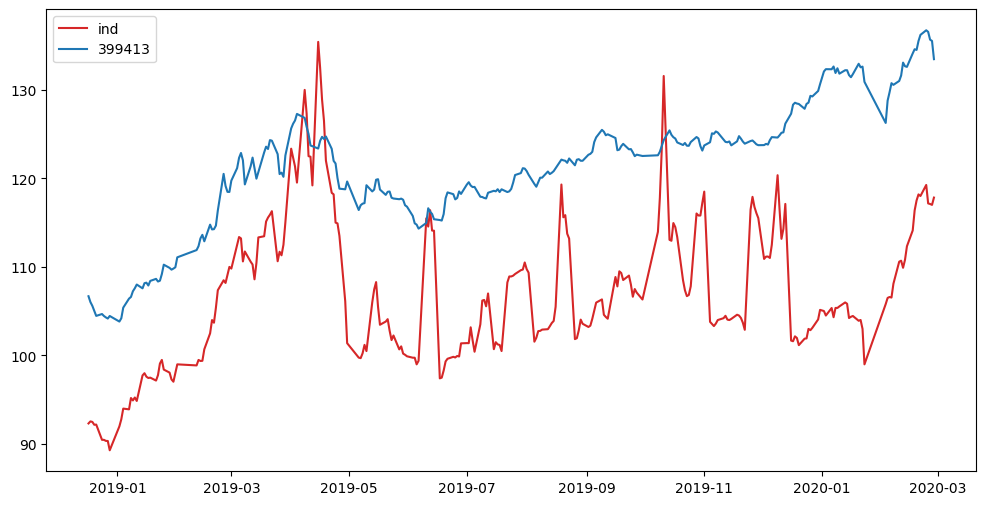

In [297]:
plt.plot(inds_all_df.loc[:'2020-02-29','ind'], color='tab:red', label='ind')
plt.plot(inds_all_df.loc[:'2020-02-29','close'], color='tab:blue', label='399413')

plt.legend()
plt.show()

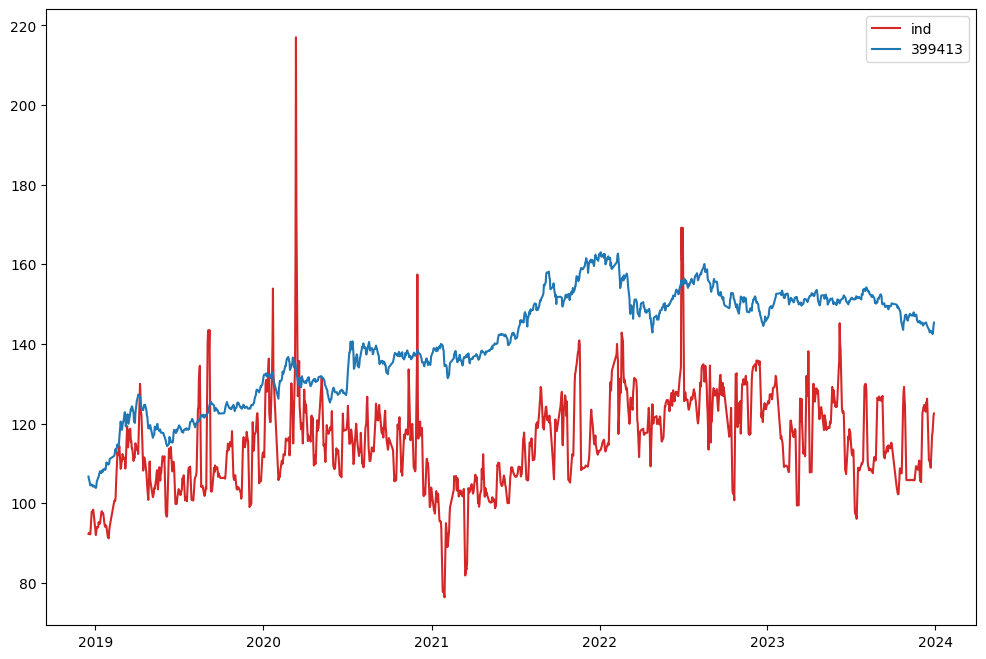

In [283]:
plt.plot(inds_all_df['ind'], color='tab:red', label='ind')
plt.plot(inds_all_df['close'], color='tab:blue', label='399413')

plt.legend()
plt.show()

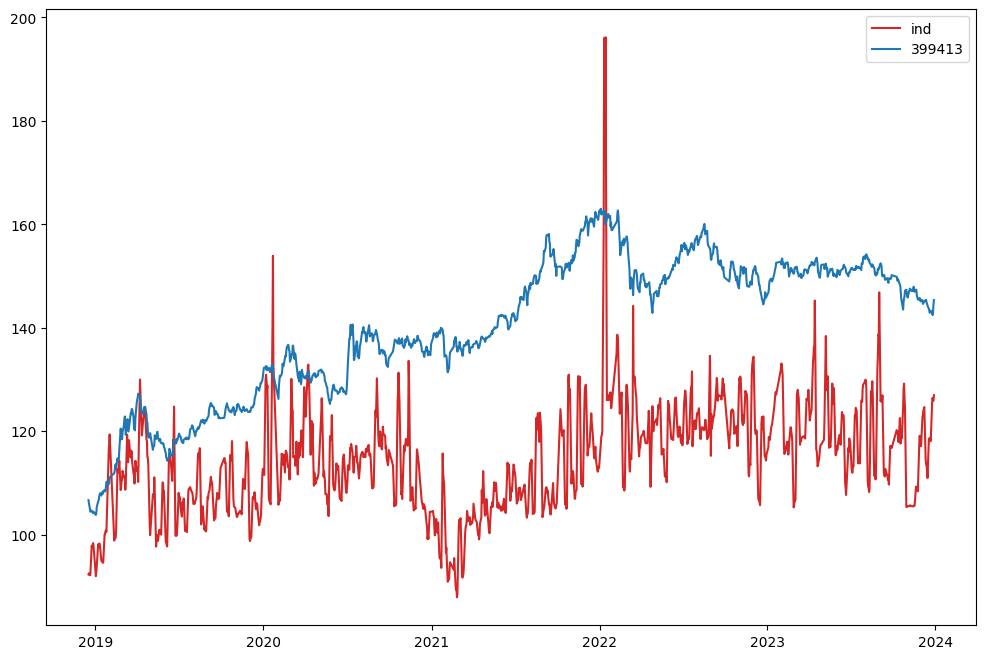

In [263]:
plt.plot(inds_all_df['ind'], color='tab:red', label='ind')
plt.plot(inds_all_df['close'], color='tab:blue', label='399413')

plt.legend()
plt.show()

In [207]:
cash_df = pd.DataFrame(cashs, columns=['date', 'cash'])

### cash

In [208]:
cash_df = cash_df.set_index(pd.to_datetime(cash_df['date']), drop=True, inplace=False)

In [209]:
cash_df

,date,cash
date,,
2018-01-02,2018-01-02,1000000.0
2018-01-03,2018-01-03,1000000.0
2018-01-04,2018-01-04,1000000.0
2018-01-05,2018-01-05,1000000.0
2018-01-06,2018-01-06,1000000.0
...,...,...
2023-12-28,2023-12-28,1223155.1
2023-12-29,2023-12-29,1222796.6
2023-12-30,2023-12-30,1195779.6


In [210]:
dddddf_10 = cash_df.merge(df_399413.close, left_index=True, right_index=True)

In [211]:
ddd = dddddf_10

In [212]:
ddd[ddd['cash'] > 2500000]

,date,cash,close
date,,,


In [213]:
# ddd = dddddf_10[dddddf_10['date'] > '2021-06-01']

In [214]:
ddd['cash_p'] = ddd['cash'] / ddd['cash'].iloc[0]
ddd['close_p'] = ddd['close'] / ddd['close'].iloc[0]

In [215]:
ddd

,date,cash,close,cash_p,close_p
date,,,,,
2018-01-02,2018-01-02,1000000.0,106.92,1.000000,1.000000
2018-01-03,2018-01-03,1000000.0,108.29,1.000000,1.012813
2018-01-04,2018-01-04,1000000.0,108.49,1.000000,1.014684
2018-01-05,2018-01-05,1000000.0,109.48,1.000000,1.023943
2018-01-08,2018-01-08,1000000.0,109.52,1.000000,1.024317
...,...,...,...,...,...
2023-12-25,2023-12-25,1217690.6,143.07,1.217691,1.338103
2023-12-26,2023-12-26,1219648.1,142.46,1.219648,1.332398
2023-12-27,2023-12-27,1221109.1,143.01,1.221109,1.337542


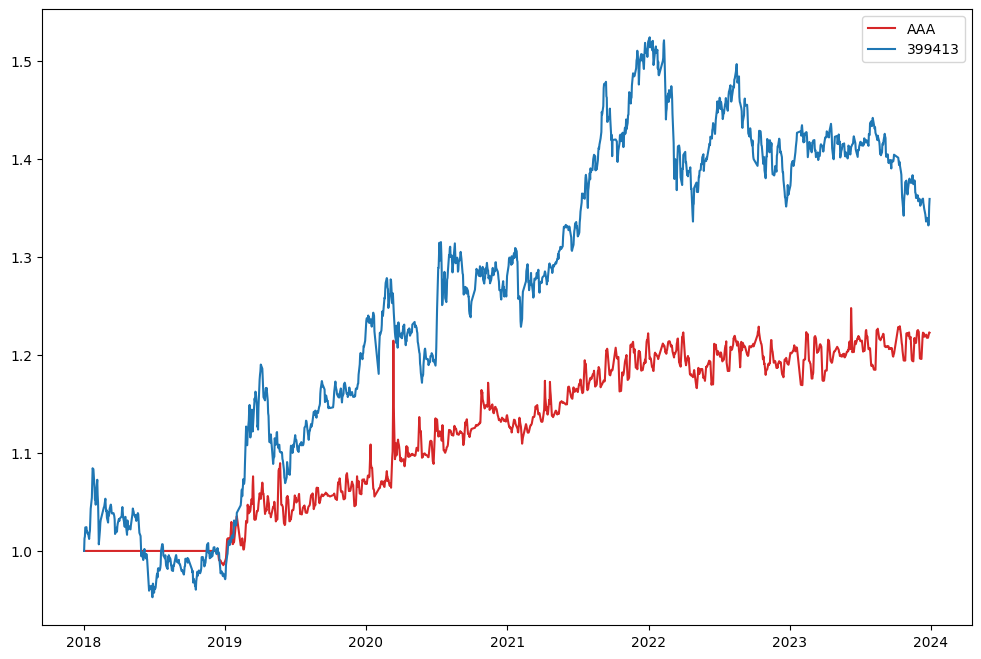

In [216]:
plt.plot(ddd['cash_p'], color='tab:red', label='AAA')
plt.plot(ddd['close_p'], color='tab:blue', label='399413')

plt.legend()
plt.show()

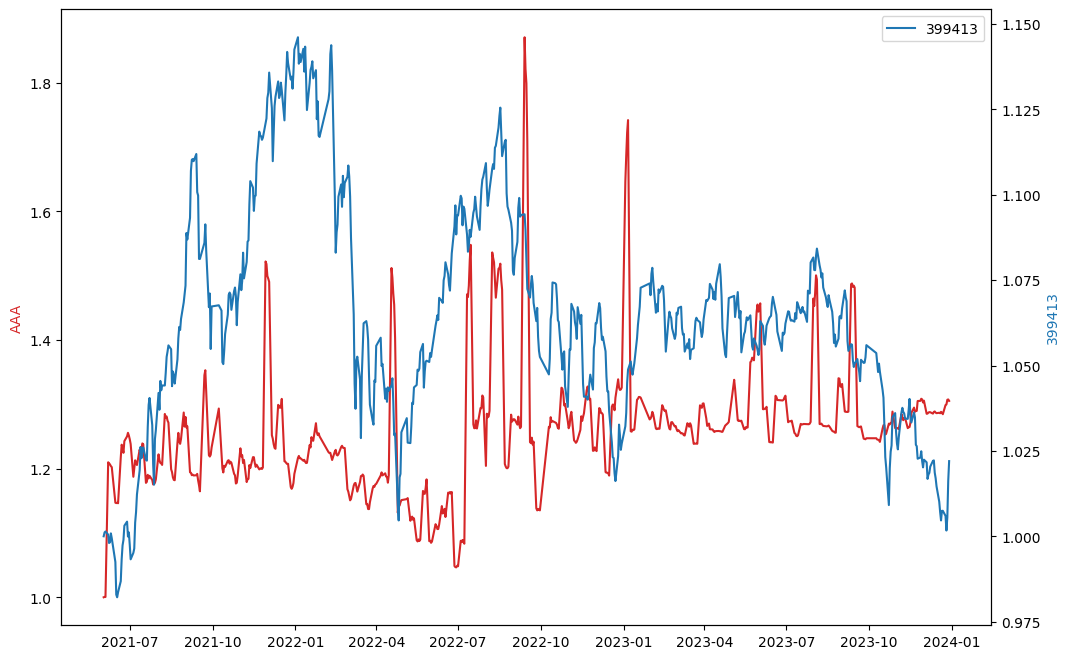

In [177]:
fig, ax1 = plt.subplots()

color = 'tab:red'
# ax1.set_xlabel('time (s)')
ax1.set_ylabel('AAA', color=color)
ax1.plot(ddd.cash_p, color=color, label='AAA')

ax2 = ax1.twinx()  # instantiate a second axes that shares the same x-axis

color = 'tab:blue'
ax2.set_ylabel('399413', color=color)  # we already handled the x-label with ax1
ax2.plot(ddd.close_p, color=color, label='399413')

# fig.tight_layout()  # otherwise the right y-label is slightly clipped
plt.legend()
plt.show()

In [139]:
dddddf_20 = cash_df.merge(ddd.close, left_index=True, right_index=True)
# df.merge(ddf, left_on='date', right_index=True)

In [140]:
dddddf_20

,date,cash,close
date,,,
2018-12-17,2018-12-17,800755.0,106.69
2018-12-17,2018-12-17,800755.0,106.69
2018-12-17,2018-12-17,800755.0,106.69
2018-12-17,2018-12-17,800755.0,106.69
2018-12-17,2018-12-17,800755.0,106.69
...,...,...,...
2023-12-29,2023-12-29,1168588.0,145.35
2023-12-29,2023-12-29,1168588.0,145.35
2023-12-29,2023-12-29,1168588.0,145.35


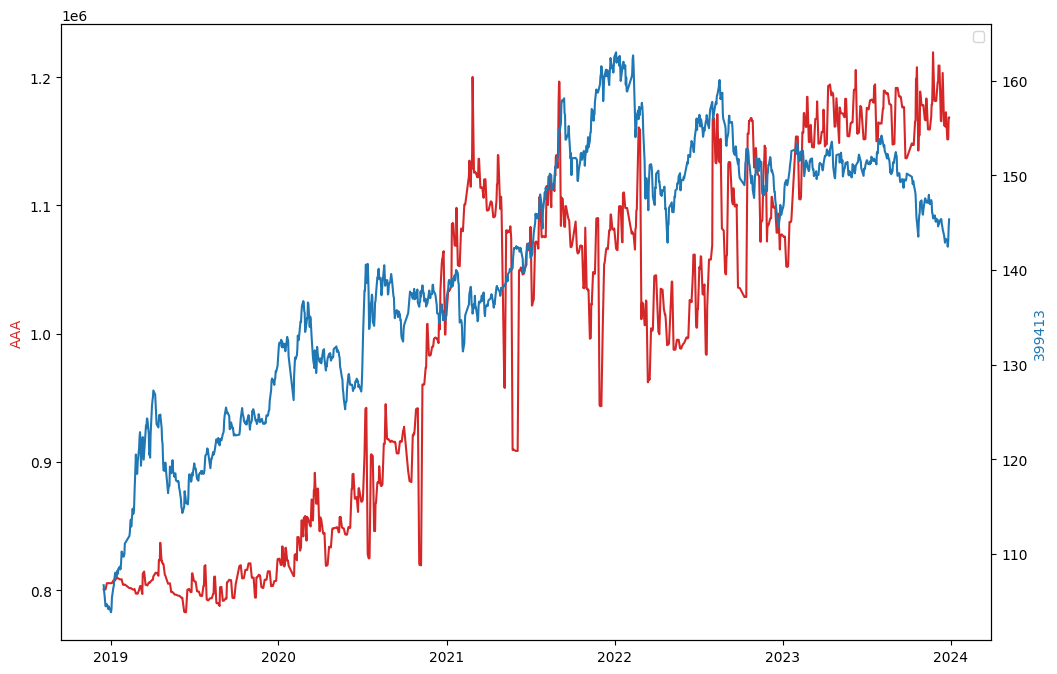

In [141]:
fig, ax1 = plt.subplots()

color = 'tab:red'
# ax1.set_xlabel('time (s)')
ax1.set_ylabel('AAA', color=color)
ax1.plot(dddddf_20.cash, color=color, label='AAA')

ax2 = ax1.twinx()  # instantiate a second axes that shares the same x-axis

color = 'tab:blue'
ax2.set_ylabel('399413', color=color)  # we already handled the x-label with ax1
ax2.plot(dddddf_20.close, color=color, label='399413')

# fig.tight_layout()  # otherwise the right y-label is slightly clipped
plt.legend()
plt.show()

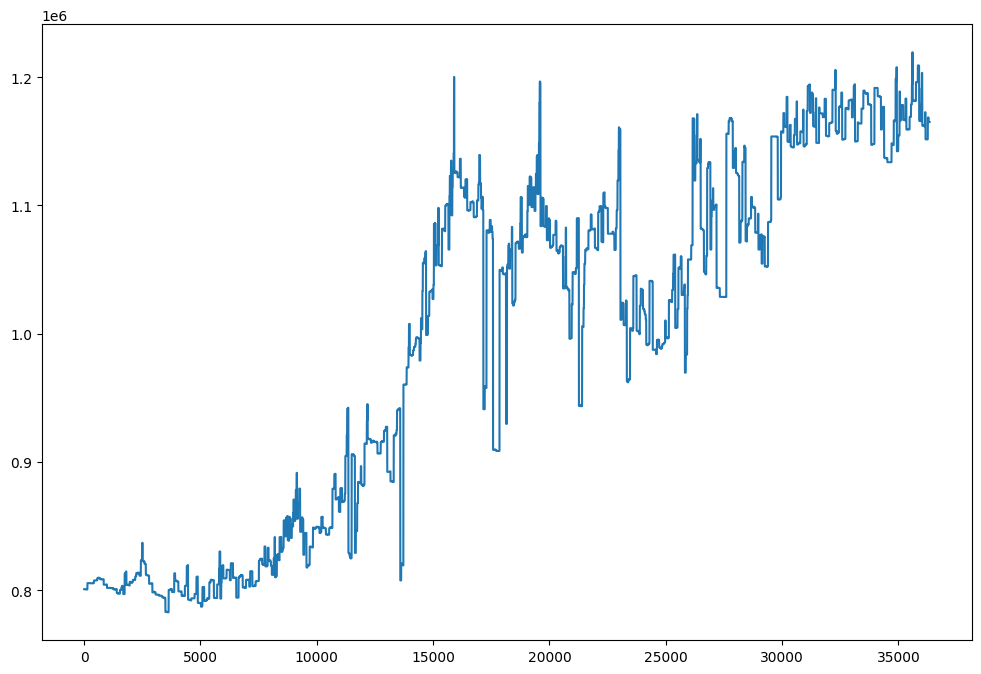

In [110]:
plt.plot(cash_df['cash'])

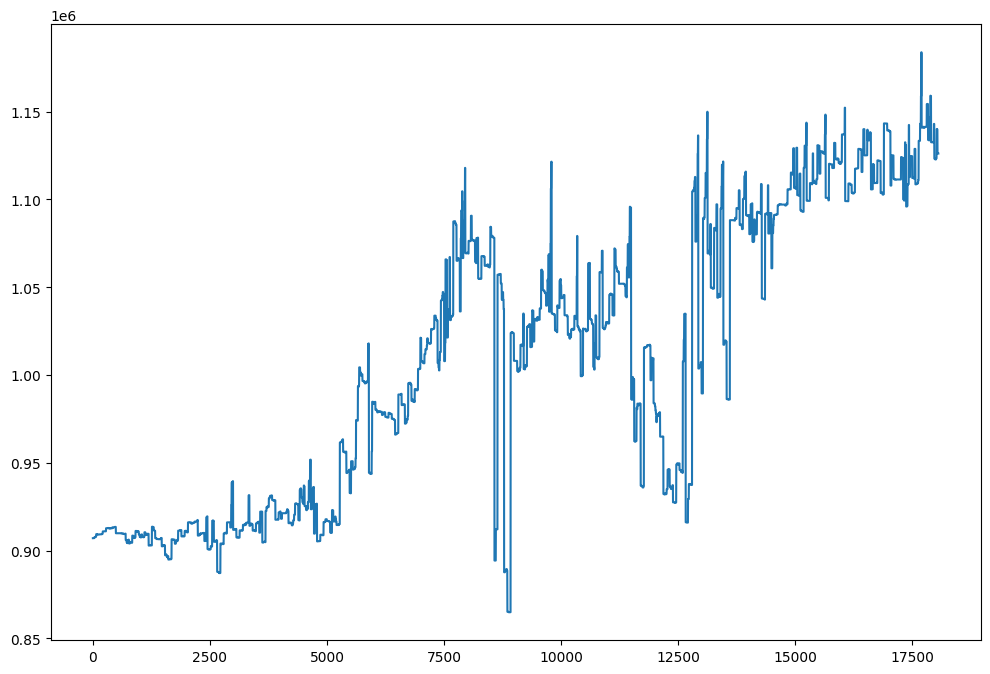

In [104]:
plt.plot(cash_df['cash'], '-')